# SegFormer Semantic Segmentation — SEM / Wafer Dataset `1.coco`
### Kaggle Notebook — COCO masks → 2x augmentation → SegFormer (AdamW, dataset-sized epochs) → Loss graph, Confusion Matrix, Precision/Recall/Accuracy/F1

Trains on **only the `1.coco` folder** (approx. 26 train / 7 valid / 4 test). This is a standalone notebook — it doesn't
mix in any other dataset version.

**What this notebook does, step by step:**
1. Locates the `1.coco` folder under `/kaggle/input/` (train/valid/test, each with `_annotations.coco.json`).
2. Converts COCO polygon annotations into pixel-wise segmentation masks.
3. Builds a SEM-tuned augmentation pipeline (Albumentations) and **doubles the training set** (original copy + one augmented copy).
4. Fine-tunes **SegFormer (MiT-B0 backbone)** from HuggingFace `transformers`, optimized with **AdamW**.
5. **Sets the number of epochs automatically from this dataset's size** — targets a roughly constant total number of gradient updates, clipped to a sane range, with early stopping as a safety net.
6. Plots the **training / validation loss curve**.
7. Evaluates on Train / Validation / Test: a **pixel-wise confusion matrix** (test set) and a **comparison table** — Precision / Recall / Accuracy / F1 Score, one row per split.
8. Checks the Test F1 against your **target F1 ≥ 0.85** and prints concrete tuning suggestions if it falls short.
9. Shows predictions on up to **10 random test images**.
10. Saves the model, plots, and metrics table to `/kaggle/working/`.

> ⚠️ A specific F1 value depends on your actual images/labels/training run — this notebook is built to make 0.85
> realistic on a clean small dataset, but the number isn't hard-coded anywhere. Section 16 tells you exactly what
> to try if you fall short. With only 26 train / 7 valid / 4 test, expect metrics (especially on tiny test splits) to be noisy —
> a couple of misclassified pixels can swing the score a lot when there are only a handful of test images.

**Before running on Kaggle:**
1. New Notebook → **Add Data** → attach the dataset that contains the `1.coco` folder.
2. **Settings → Accelerator → GPU** (T4 x2 or P100).
3. Run all cells top to bottom (`Run All`).

## 1. Install & import

In [5]:
!pip install -q -U transformers albumentations pycocotools opencv-python-headless

In [6]:
import os, json, glob, random, copy, math, re
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, ConcatDataset
import albumentations as A
from pycocotools.coco import COCO
from transformers import SegformerForSemanticSegmentation
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, accuracy_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

Device: cuda


## 2. Locate the `1.coco` dataset
Searches `/kaggle/input/` for a folder whose name **ends with** `1.coco` — this matches an exact folder
named `1.coco` just as well as something like `SEM wafer dataset-Folder- 1.coco` (Kaggle sometimes
keeps the full original folder name on upload). If your folder is named very differently, edit `TARGET_FOLDER_NAME`
below.

In [7]:
TARGET_FOLDER_NAME = "1.coco"

# Matches folders that END with the target token (e.g. "SEM wafer dataset-Folder- 1.coco"),
# not just an exact name - but guards against "1.coco" wrongly matching inside "21.coco".
_pattern = re.compile(r"(?<![0-9])" + re.escape(TARGET_FOLDER_NAME) + r"$")

hits = glob.glob("/kaggle/input/**/train/_annotations.coco.json", recursive=True)
matches = [h for h in hits
           if _pattern.search(os.path.basename(os.path.dirname(os.path.dirname(h))))]

if not matches:
    all_found = sorted(set(os.path.basename(os.path.dirname(os.path.dirname(h))) for h in hits))
    raise FileNotFoundError(
        f"No folder ending in '{TARGET_FOLDER_NAME}' found under /kaggle/input. "
        f"Folders that WERE found: {all_found}. "
        "Update TARGET_FOLDER_NAME above to match, or check 'Add Data'."
    )

DATA_ROOT = os.path.dirname(os.path.dirname(matches[0]))
print("Using dataset folder:", DATA_ROOT)

TRAIN_DIR = os.path.join(DATA_ROOT, "train")
VALID_DIR = os.path.join(DATA_ROOT, "valid")
TEST_DIR  = os.path.join(DATA_ROOT, "test")

for split_dir in (TRAIN_DIR, VALID_DIR, TEST_DIR):
    n_imgs = len([f for f in os.listdir(split_dir) if f.lower().endswith((".jpg", ".jpeg", ".png"))])
    print(f"{split_dir}: {n_imgs} images")

Using dataset folder: /kaggle/input/datasets/hackathon07/sem-dataset-1/SEM wafer dataset-Folder- 1.coco
/kaggle/input/datasets/hackathon07/sem-dataset-1/SEM wafer dataset-Folder- 1.coco/train: 26 images
/kaggle/input/datasets/hackathon07/sem-dataset-1/SEM wafer dataset-Folder- 1.coco/valid: 7 images
/kaggle/input/datasets/hackathon07/sem-dataset-1/SEM wafer dataset-Folder- 1.coco/test: 4 images


## 3. Read COCO annotations & build the class map

In [8]:
coco_train = COCO(os.path.join(TRAIN_DIR, "_annotations.coco.json"))
coco_valid = COCO(os.path.join(VALID_DIR, "_annotations.coco.json"))
coco_test  = COCO(os.path.join(TEST_DIR,  "_annotations.coco.json"))

cats = coco_train.loadCats(coco_train.getCatIds())
cats = sorted(cats, key=lambda c: c["id"])
print("Categories found in COCO json:", cats)

drop_names = {"nothing", "background"}
if any(c["name"].lower() in drop_names for c in cats):
    cats = [c for c in cats if c["name"].lower() not in drop_names]

id2label = {0: "background"}
cat_id_to_label_id = {}
for i, c in enumerate(cats, start=1):
    id2label[i] = c["name"]
    cat_id_to_label_id[c["id"]] = i
label2id = {v: k for k, v in id2label.items()}

NUM_CLASSES = len(id2label)
print("id2label:", id2label)
print("NUM_CLASSES:", NUM_CLASSES)

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Categories found in COCO json: [{'id': 0, 'name': 'SEM-wafer-dataset', 'supercategory': 'none'}, {'id': 1, 'name': 'SEM-wafer-dataset', 'supercategory': 'SEM-wafer-dataset'}]
id2label: {0: 'background', 1: 'SEM-wafer-dataset', 2: 'SEM-wafer-dataset'}
NUM_CLASSES: 3


## 4. COCO polygons → pixel masks

In [9]:
def _clean_segmentation(seg):
    """Drop degenerate polygons that crash pycocotools (empty, <3 points, odd coord count)."""
    if isinstance(seg, list):
        valid = [p for p in seg if isinstance(p, list) and len(p) >= 6 and len(p) % 2 == 0]
        return valid if valid else None
    return seg  # RLE dict form - leave as-is

def build_mask(coco, img_info, cat_map):
    """Rasterize all annotations for one image into a single-channel class-id mask.
    Malformed annotations (bad polygons) are skipped with a warning instead of crashing."""
    h, w = img_info["height"], img_info["width"]
    mask = np.zeros((h, w), dtype=np.uint8)  # 0 = background
    ann_ids = coco.getAnnIds(imgIds=img_info["id"])
    anns = coco.loadAnns(ann_ids)
    for ann in anns:
        if ann["category_id"] not in cat_map:
            continue
        seg = ann.get("segmentation")
        if not seg:
            continue
        seg_clean = _clean_segmentation(seg)
        if seg_clean is None:
            print(f"Skipping empty/degenerate polygon: ann id={ann.get('id')} img={img_info.get('file_name')}")
            continue
        try:
            ann_for_mask = ann if seg_clean is seg else {**ann, "segmentation": seg_clean}
            m = coco.annToMask(ann_for_mask)
        except Exception as e:
            print(f"Skipping unrasterizable annotation id={ann.get('id')} img={img_info.get('file_name')}: {e}")
            continue
        mask[m == 1] = cat_map[ann["category_id"]]
    return mask

def list_split(coco, img_dir):
    items = []
    for img_id in coco.getImgIds():
        info = coco.loadImgs(img_id)[0]
        path = os.path.join(img_dir, info["file_name"])
        if os.path.exists(path):
            items.append((path, info))
    return items

train_items = list_split(coco_train, TRAIN_DIR)
valid_items = list_split(coco_valid, VALID_DIR)
test_items  = list_split(coco_test,  TEST_DIR)
print(f"train={len(train_items)}  valid={len(valid_items)}  test={len(test_items)}")

train=26  valid=7  test=4


## 5. Visualize a sample image + mask

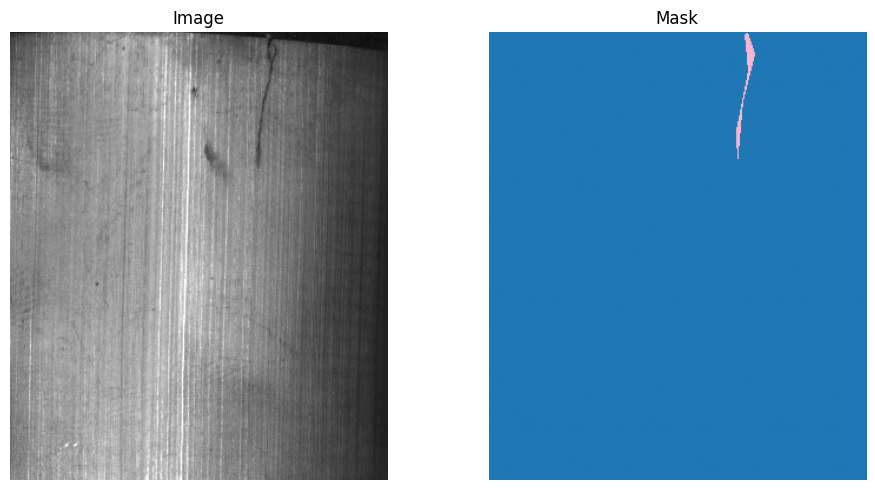

In [10]:
def show_sample(coco, items, idx=0):
    path, info = items[idx]
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    mask = build_mask(coco, info, cat_id_to_label_id)
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(img); ax[0].set_title("Image"); ax[0].axis("off")
    ax[1].imshow(mask, cmap="tab20", vmin=0, vmax=NUM_CLASSES); ax[1].set_title("Mask"); ax[1].axis("off")
    plt.tight_layout(); plt.show()

show_sample(coco_train, train_items, 0)

## 6. Augmentation pipeline (SEM-tuned) — doubles the training set
SEM/wafer images carry no real color information and are texture-heavy, so the pipeline favors geometric transforms
plus sensor-realistic noise/blur over color jitter.

`base_transform` = resize + normalize only (no randomness) — used for the "original" copy, and for valid/test.
`aug_transform` = the same, plus flips/rotation/affine/noise/blur/brightness/grid-distortion — used for the augmented copy.

In [11]:
IMG_SIZE = 512
MEAN = (0.485, 0.456, 0.406)
STD  = (0.229, 0.224, 0.225)

base_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=MEAN, std=STD),
])

aug_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.Affine(translate_percent=0.05, scale=(0.9, 1.1), rotate=(-15, 15),
              border_mode=cv2.BORDER_REFLECT, p=0.5),
    A.OneOf([
        A.GaussNoise(std_range=(0.02, 0.1)),
        A.MultiplicativeNoise(multiplier=(0.9, 1.1)),
    ], p=0.4),
    A.OneOf([
        A.GaussianBlur(blur_limit=(3, 5)),
        A.MotionBlur(blur_limit=3),
    ], p=0.3),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
    A.GridDistortion(num_steps=5, distort_limit=0.1, p=0.2),
    A.Normalize(mean=MEAN, std=STD),
])

## 7. PyTorch Dataset

In [12]:
class SEMSegDataset(Dataset):
    def __init__(self, coco, items, cat_map, transform):
        self.coco, self.items, self.cat_map, self.transform = coco, items, cat_map, transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        path, info = self.items[idx]
        img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        mask = build_mask(self.coco, info, self.cat_map)
        out = self.transform(image=img, mask=mask)
        pixel_values = torch.tensor(out["image"]).permute(2, 0, 1).float()
        label = torch.tensor(out["mask"]).long()
        return {"pixel_values": pixel_values, "labels": label}

# "Augment the dataset twice": training set = originals (resize+normalize only)
# CONCATENATED with an augmented copy (full random augmentation) -> 2x samples/epoch.
train_plain = SEMSegDataset(coco_train, train_items, cat_id_to_label_id, base_transform)
train_aug   = SEMSegDataset(coco_train, train_items, cat_id_to_label_id, aug_transform)
train_dataset = ConcatDataset([train_plain, train_aug])

valid_dataset = SEMSegDataset(coco_valid, valid_items, cat_id_to_label_id, base_transform)
test_dataset  = SEMSegDataset(coco_test,  test_items,  cat_id_to_label_id, base_transform)

print("Train samples (2x augmented):", len(train_dataset))
print("Valid samples:", len(valid_dataset))
print("Test samples:", len(test_dataset))

Train samples (2x augmented): 52
Valid samples: 7
Test samples: 4


## 8. DataLoaders

In [13]:
BATCH_SIZE = 4  # small dataset -> keep batch size modest

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=1,          shuffle=False, num_workers=2, pin_memory=True)

## 9. Class weights (handle imbalance) + model
Wafer defect masks are almost always background-dominant. Weighting the loss by inverse pixel frequency
usually helps recall/F1 on the minority (defect) class.

In [14]:
class_pixels = np.zeros(NUM_CLASSES, dtype=np.int64)
for path, info in train_items:
    m = build_mask(coco_train, info, cat_id_to_label_id)
    counts = np.bincount(m.flatten(), minlength=NUM_CLASSES)
    class_pixels += counts

freq = class_pixels / class_pixels.sum()
class_weights = 1.0 / np.log(1.02 + freq)          # log-smoothed inverse frequency
class_weights = class_weights / class_weights.mean()
class_weights_t = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)
print("Class pixel freq:", dict(zip(id2label.values(), freq.round(4))))
print("Class weights   :", dict(zip(id2label.values(), class_weights.round(3))))

Class pixel freq: {'background': np.float64(0.9964), 'SEM-wafer-dataset': np.float64(0.0036)}
Class weights   : {'background': np.float64(0.045), 'SEM-wafer-dataset': np.float64(1.357)}


### About the warnings you'll see loading `nvidia/mit-b0`
Two things below are **expected, not errors**:
- *"You are sending unauthenticated requests to the HF Hub"* — just means downloads use the public rate limit; harmless for a one-time model download. Ignore it, or add an `HF_TOKEN` as a Kaggle Secret if you want faster/higher-limit downloads.
- *"num_labels=X incompatible with id2label map of length 1000"* + a LOAD REPORT with `classifier` as UNEXPECTED and `decode_head.*` as MISSING — `nvidia/mit-b0` is an ImageNet-pretrained **backbone only** checkpoint (1000-class classifier, no segmentation head). Loading it for segmentation correctly discards that ImageNet classifier and randomly initializes a fresh decode head sized to your `NUM_CLASSES` — the encoder weights that actually matter for transfer learning do carry over. `set_verbosity_error()` below just quiets the noisy report; the "Trainable params" line printed after is your real confirmation it loaded.

In [15]:
from transformers import logging as hf_logging
hf_logging.set_verbosity_error()  # suppress the informational (expected) load-report noise explained above

model = SegformerForSemanticSegmentation.from_pretrained(
    "nvidia/mit-b0",
    num_labels=NUM_CLASSES,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
).to(DEVICE)

criterion = nn.CrossEntropyLoss(weight=class_weights_t, ignore_index=255)
print(f"Model loaded. Trainable params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/14.4M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

Model loaded. Trainable params: 3,714,915


## 10. Training — AdamW optimizer, epochs sized to this dataset
Instead of a fixed epoch count, `EPOCHS` is derived from how many training samples this specific folder has (after
2x augmentation): the target is a roughly constant total number of gradient updates (`TARGET_UPDATES`), clipped to a
sane `[MIN_EPOCHS, MAX_EPOCHS]` range, with early stopping (`PATIENCE`) as a safety net either way.

In [16]:
TARGET_UPDATES = 2000     # roughly how many gradient steps a MiT-B0 fine-tune on this data size wants
MIN_EPOCHS, MAX_EPOCHS = 25, 150
LR = 6e-5
WEIGHT_DECAY = 1e-4
PATIENCE = 8

steps_per_epoch = math.ceil(len(train_dataset) / BATCH_SIZE)
EPOCHS = int(np.clip(round(TARGET_UPDATES / steps_per_epoch), MIN_EPOCHS, MAX_EPOCHS))
print(f"Train set: {len(train_dataset)} samples (2x aug) | batch={BATCH_SIZE} | steps/epoch={steps_per_epoch}")
print(f"-> EPOCHS set to {EPOCHS} (~{EPOCHS * steps_per_epoch} total gradient updates)")

optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def forward_loss(model, pixel_values, labels):
    outputs = model(pixel_values=pixel_values)
    logits = outputs.logits
    logits_up = nn.functional.interpolate(logits, size=labels.shape[-2:], mode="bilinear", align_corners=False)
    loss = criterion(logits_up, labels)
    return loss, logits_up

def run_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, n_batches = 0.0, 0
    with torch.set_grad_enabled(train):
        for batch in loader:
            pixel_values = batch["pixel_values"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)
            if train:
                optimizer.zero_grad()
            loss, _ = forward_loss(model, pixel_values, labels)
            if train:
                loss.backward()
                optimizer.step()
            total_loss += loss.item()
            n_batches += 1
    return total_loss / max(n_batches, 1)

Train set: 52 samples (2x aug) | batch=4 | steps/epoch=13
-> EPOCHS set to 150 (~1950 total gradient updates)


In [17]:
history = {"train_loss": [], "val_loss": []}
best_val_loss = float("inf")
best_state = None
patience_ctr = 0

for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(train_loader, train=True)
    val_loss = run_epoch(valid_loader, train=False)
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"Epoch {epoch:02d}/{EPOCHS} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f}")

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        patience_ctr = 0
    else:
        patience_ctr += 1
        if patience_ctr >= PATIENCE:
            print(f"Early stopping at epoch {epoch} (no val improvement for {PATIENCE} epochs).")
            break

model.load_state_dict(best_state)
print(f"Loaded best model (val_loss={best_val_loss:.4f}).")

model.safetensors:   0%|          | 0.00/14.3M [00:00<?, ?B/s]

Epoch 01/150 | train_loss=0.9825 | val_loss=1.0361
Epoch 02/150 | train_loss=0.8428 | val_loss=0.9396
Epoch 03/150 | train_loss=0.7365 | val_loss=0.8353
Epoch 04/150 | train_loss=0.6372 | val_loss=0.6831
Epoch 05/150 | train_loss=0.5516 | val_loss=0.5559
Epoch 06/150 | train_loss=0.4901 | val_loss=0.4361
Epoch 07/150 | train_loss=0.4502 | val_loss=0.3565
Epoch 08/150 | train_loss=0.4060 | val_loss=0.3734
Epoch 09/150 | train_loss=0.3804 | val_loss=0.2949
Epoch 10/150 | train_loss=0.3613 | val_loss=0.2667
Epoch 11/150 | train_loss=0.3247 | val_loss=0.2562
Epoch 12/150 | train_loss=0.3064 | val_loss=0.2921
Epoch 13/150 | train_loss=0.2777 | val_loss=0.2490
Epoch 14/150 | train_loss=0.2479 | val_loss=0.1686
Epoch 15/150 | train_loss=0.2415 | val_loss=0.2079
Epoch 16/150 | train_loss=0.2303 | val_loss=0.1613
Epoch 17/150 | train_loss=0.2177 | val_loss=0.1768
Epoch 18/150 | train_loss=0.1992 | val_loss=0.1628
Epoch 19/150 | train_loss=0.1882 | val_loss=0.1401
Epoch 20/150 | train_loss=0.176

## 11. Loss graph

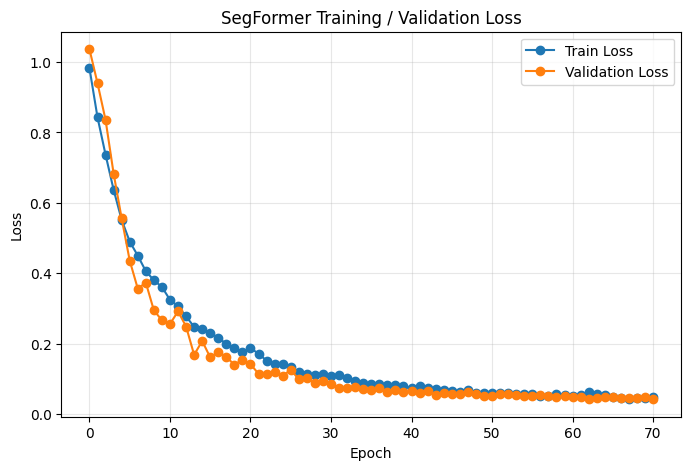

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], label="Train Loss", marker="o")
plt.plot(history["val_loss"], label="Validation Loss", marker="o")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("SegFormer Training / Validation Loss")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("/kaggle/working/loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Evaluate on Train / Validation / Test
`predict_mask` runs the model; `evaluate_dataset` scores a whole split. **Train is evaluated with `train_plain`
(resize+normalize only, no random augmentation)** so the score reflects real performance, not augmented pixels.

In [19]:
@torch.no_grad()
def predict_mask(model, pixel_values, out_hw):
    outputs = model(pixel_values=pixel_values.to(DEVICE))
    logits_up = nn.functional.interpolate(outputs.logits, size=out_hw, mode="bilinear", align_corners=False)
    return logits_up.argmax(dim=1).cpu().numpy()

@torch.no_grad()
def evaluate_dataset(dataset, batch_size=4):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
    model.eval()
    all_preds, all_labels = [], []
    for batch in loader:
        pixel_values = batch["pixel_values"]
        labels = batch["labels"].numpy()
        pred = predict_mask(model, pixel_values, labels.shape[-2:])
        all_preds.append(pred.reshape(-1))
        all_labels.append(labels.reshape(-1))
    y_pred = np.concatenate(all_preds)
    y_true = np.concatenate(all_labels)

    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(NUM_CLASSES)), average="weighted", zero_division=0
    )
    metrics = {"Precision": precision, "Recall": recall, "Accuracy": acc, "F1 Score": f1}
    return metrics, y_true, y_pred

split_metrics = {}
split_metrics["Train"],      y_true_train, y_pred_train = evaluate_dataset(train_plain)
split_metrics["Validation"], y_true_valid, y_pred_valid = evaluate_dataset(valid_dataset)
split_metrics["Test"],       y_true_test,  y_pred_test  = evaluate_dataset(test_dataset)

split_preds = {
    "Train": (y_true_train, y_pred_train),
    "Validation": (y_true_valid, y_pred_valid),
    "Test": (y_true_test, y_pred_test),
}

for split, m in split_metrics.items():
    print(split, {k: round(v, 4) for k, v in m.items()})

Train {'Precision': 0.9971, 'Recall': 0.9907, 'Accuracy': 0.9907, 'F1 Score': 0.9931}
Validation {'Precision': 0.9976, 'Recall': 0.9927, 'Accuracy': 0.9927, 'F1 Score': 0.9946}
Test {'Precision': 0.9989, 'Recall': 0.9936, 'Accuracy': 0.9936, 'F1 Score': 0.9959}


## 13. Comparison table — Precision / Recall / Accuracy / F1 Score

In [20]:
comparison_df = pd.DataFrame(split_metrics).T.reset_index().rename(columns={"index": "Dataset"})
comparison_df = comparison_df[["Dataset", "Precision", "Recall", "Accuracy", "F1 Score"]].round(4)

comparison_df.to_csv("/kaggle/working/metrics_comparison_table.csv", index=False)
comparison_df

,Dataset,Precision,Recall,Accuracy,F1 Score
0,Train,0.9971,0.9907,0.9907,0.9931
1,Validation,0.9976,0.9927,0.9927,0.9946
2,Test,0.9989,0.9936,0.9936,0.9959


## 14. Confusion Matrix (Test set)

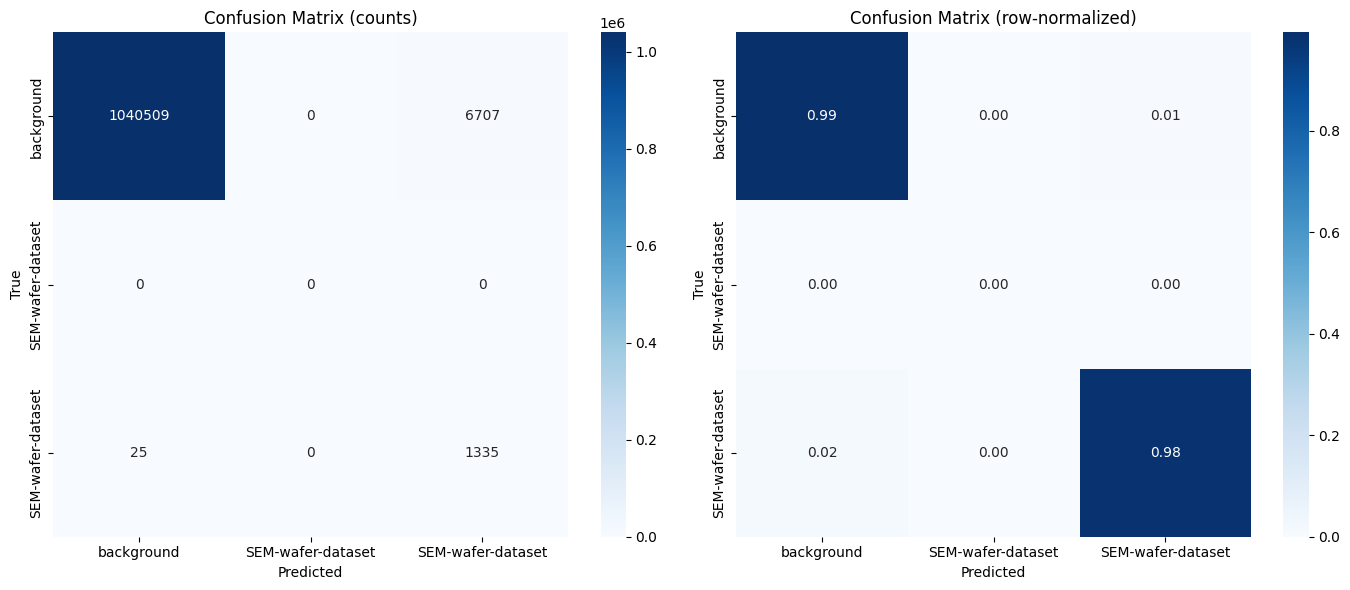

In [21]:
y_true, y_pred = split_preds["Test"]
labels_order = list(range(NUM_CLASSES))
cm = confusion_matrix(y_true, y_pred, labels=labels_order)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[id2label[i] for i in labels_order],
            yticklabels=[id2label[i] for i in labels_order], ax=ax[0])
ax[0].set_title("Confusion Matrix (counts)"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("True")

sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=[id2label[i] for i in labels_order],
            yticklabels=[id2label[i] for i in labels_order], ax=ax[1])
ax[1].set_title("Confusion Matrix (row-normalized)"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("True")

plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## 15. Target check — F1 ≥ 0.85

In [22]:
TARGET_F1 = 0.85
achieved = split_metrics["Test"]["F1 Score"]

print(f"Target F1: {TARGET_F1:.2f}  |  Achieved (Test, weighted) F1: {achieved:.4f}")
if achieved >= TARGET_F1:
    print("Target F1 reached.")
else:
    gap = TARGET_F1 - achieved
    print(f"{gap:.4f} short of target. Highest-impact things to try, in order:")
    print(" 1. Check annotation quality/consistency in 1.coco - noisy masks cap F1 fast, and this is a small split.")
    print(" 2. Raise TARGET_UPDATES in Section 10 (more epochs), or move up to \'nvidia/mit-b1\' for more capacity.")
    print(" 3. Strengthen augmentation, or concatenate a second augmented copy (3x instead of 2x).")
    print(" 4. Push class_weights further toward the rarer defect class (Section 9).")
    print(" 5. Re-check IMG_SIZE - very fine SEM defects can be lost at 512x512; try 640 or 768 if VRAM allows.")
    print(" 6. If it matches your real use case, filter tiny speckle blobs from predictions before scoring.")
    if split_metrics["Train"]["F1 Score"] - achieved > 0.15:
        print(" Note: Train F1 is well above Test F1 - that gap points to overfitting on a small train set;")
        print("       more/stronger augmentation or a smaller backbone will help more than more epochs.")

Target F1: 0.85  |  Achieved (Test, weighted) F1: 0.9959
Target F1 reached.


## 16. Qualitative check — up to 10 random test predictions
If this cell errors with `NameError: test_items is not defined`, an earlier cell (Sections 2-4) wasn't executed in
the *current* kernel session — usually after a Restart, or after running this cell on its own. The guard below
rebuilds `test_items` automatically if that's all that's missing, but it still needs a trained `model` in memory,
so re-run from the top (**Run All**) if the check below fails.

Showing 4 random test image(s) - indices [0, 3, 1, 2] (this dataset's test split has 4 image(s) total).


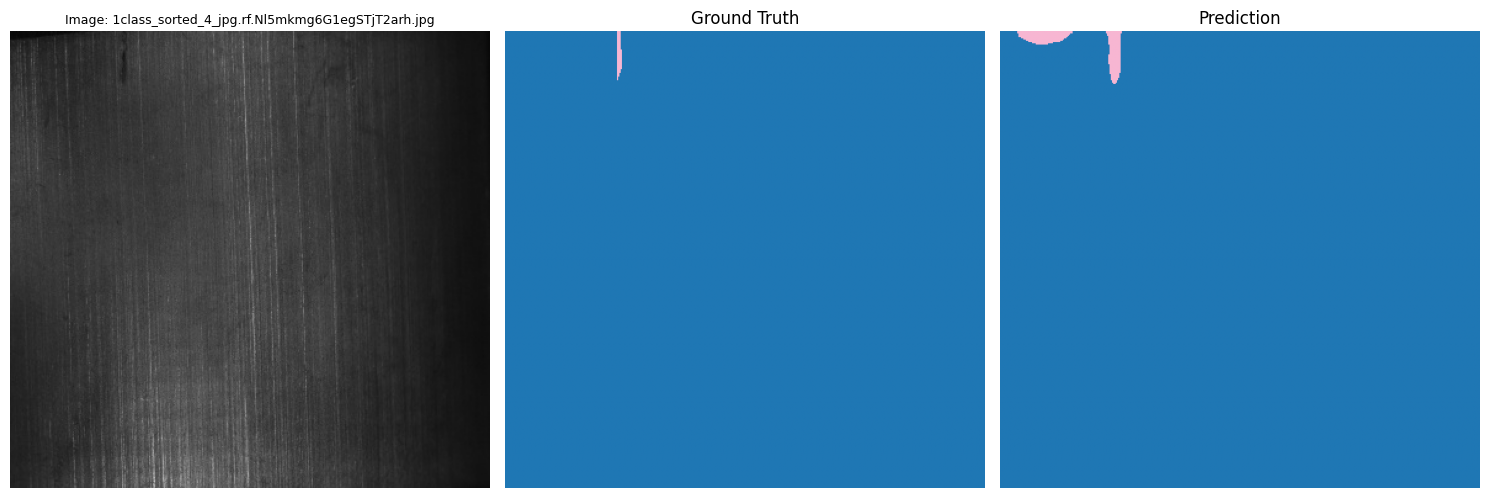

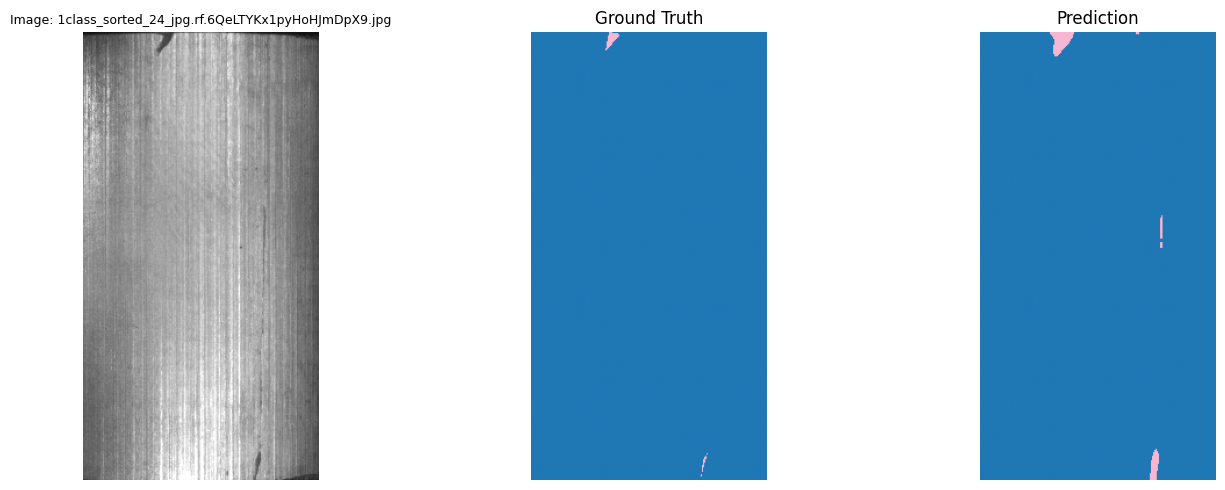

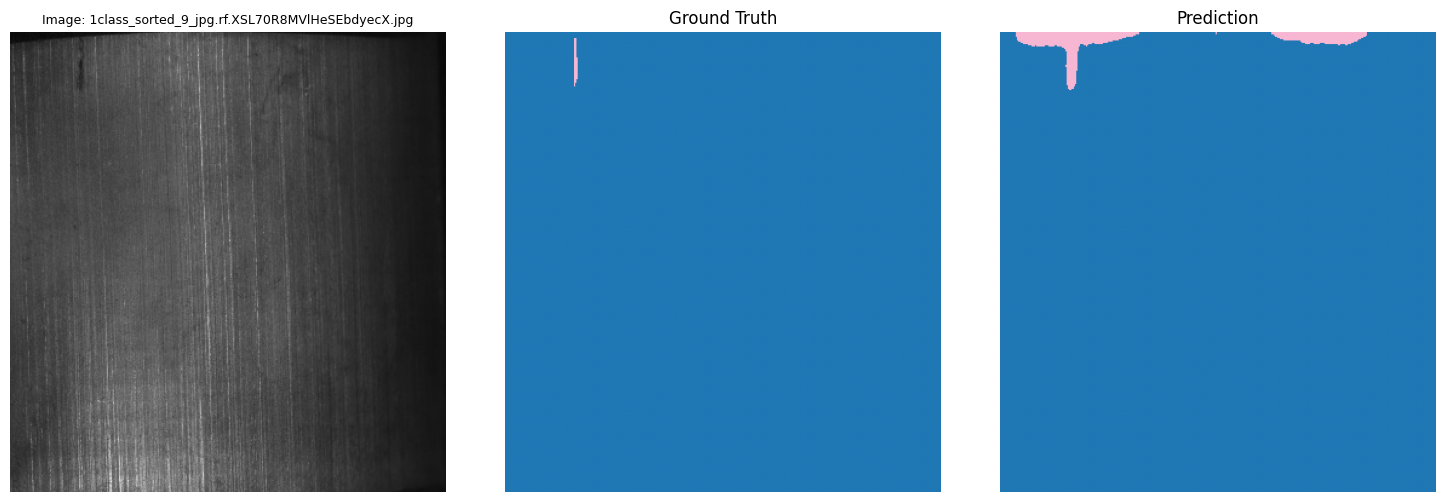

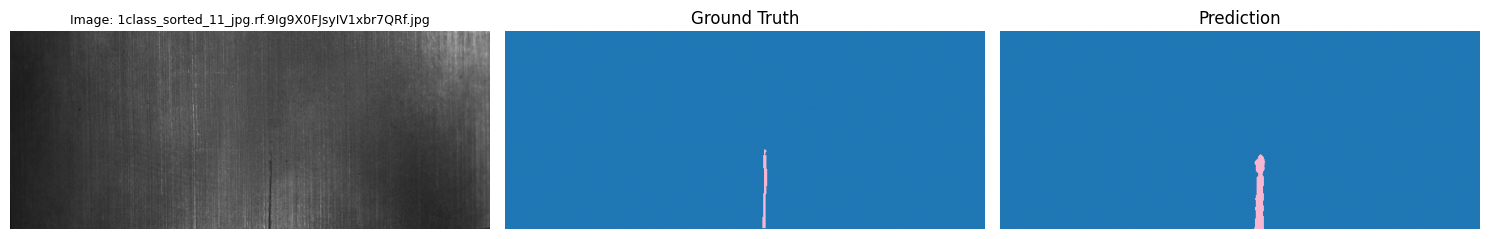

In [23]:
import random

required_vars = ["coco_test", "TEST_DIR", "cat_id_to_label_id", "NUM_CLASSES", "base_transform", "model", "predict_mask"]
missing = [v for v in required_vars if v not in globals()]
if missing:
    raise RuntimeError(
        f"Missing from this session: {missing}. Use Run All from the top of the notebook - "
        "this cell needs the dataset objects (Sections 1-4) AND the trained model (Sections 9-10) "
        "to already exist in memory."
    )

if "test_items" not in globals():
    test_items = list_split(coco_test, TEST_DIR)

def visualize_prediction(idx=0):
    path, info = test_items[idx]
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    gt_mask = build_mask(coco_test, info, cat_id_to_label_id)
    out = base_transform(image=img, mask=gt_mask)
    pixel_values = torch.tensor(out["image"]).permute(2, 0, 1).float().unsqueeze(0)
    pred_mask = predict_mask(model, pixel_values, gt_mask.shape)[0]

    fig, ax = plt.subplots(1, 3, figsize=(15, 5))
    ax[0].imshow(img); ax[0].set_title(f"Image: {info['file_name']}", fontsize=9); ax[0].axis("off")
    ax[1].imshow(gt_mask, cmap="tab20", vmin=0, vmax=NUM_CLASSES); ax[1].set_title("Ground Truth"); ax[1].axis("off")
    ax[2].imshow(pred_mask, cmap="tab20", vmin=0, vmax=NUM_CLASSES); ax[2].set_title("Prediction"); ax[2].axis("off")
    plt.tight_layout(); plt.show()

random.seed(SEED if "SEED" in globals() else 42)
n_show = min(10, len(test_items))
random_indices = random.sample(range(len(test_items)), n_show)
print(f"Showing {n_show} random test image(s) - indices {random_indices} "
      f"(this dataset's test split has {len(test_items)} image(s) total).")

for idx in random_indices:
    visualize_prediction(idx)

## 17. Save artifacts

In [24]:
os.makedirs("/kaggle/working/segformer_1coco_model", exist_ok=True)
model.save_pretrained("/kaggle/working/segformer_1coco_model")

with open("/kaggle/working/id2label_segformer_1coco_model.json", "w") as f:
    json.dump(id2label, f, indent=2)

print("Saved:")
print(" - /kaggle/working/segformer_1coco_model/  (model weights + config)")
print(" - /kaggle/working/id2label_segformer_1coco_model.json")
print(" - /kaggle/working/loss_curve.png")
print(" - /kaggle/working/confusion_matrix.png")
print(" - /kaggle/working/metrics_comparison_table.csv")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved:
 - /kaggle/working/segformer_1coco_model/  (model weights + config)
 - /kaggle/working/id2label_segformer_1coco_model.json
 - /kaggle/working/loss_curve.png
 - /kaggle/working/confusion_matrix.png
 - /kaggle/working/metrics_comparison_table.csv


In [25]:
import torch
import os

# ============================================================
# SAVE SEGFORMER MODEL AS .PTH
# ============================================================

PTH_PATH = "/kaggle/working/segformer_1coco_model.pth"

# Handle normal model or DataParallel model
if hasattr(model, "module"):
    torch.save(model.module.state_dict(), PTH_PATH)
else:
    torch.save(model.state_dict(), PTH_PATH)

# Verify
assert os.path.exists(PTH_PATH), "PTH file was not created!"

size_mb = os.path.getsize(PTH_PATH) / (1024 ** 2)

print("✅ .pth model saved successfully")
print("Path:", PTH_PATH)
print(f"Size: {size_mb:.2f} MB")

✅ .pth model saved successfully
Path: /kaggle/working/segformer_1coco_model.pth
Size: 14.26 MB


In [26]:
import os
import json
import torch

# ============================================================
# SAVE FINAL SEGFORMER MODEL
# ============================================================

HF_MODEL_DIR = "/kaggle/working/segformer_1coco_model"
PTH_PATH = "/kaggle/working/segformer_1coco_model.pth"
LABEL_PATH = "/kaggle/working/id2label_segformer_1coco_model.json"

# ------------------------------------------------------------
# 1. Save Hugging Face model + configuration
# ------------------------------------------------------------

os.makedirs(HF_MODEL_DIR, exist_ok=True)

model.save_pretrained(HF_MODEL_DIR)

# ------------------------------------------------------------
# 2. Save PyTorch .pth weights
# ------------------------------------------------------------

if hasattr(model, "module"):
    torch.save(model.module.state_dict(), PTH_PATH)
else:
    torch.save(model.state_dict(), PTH_PATH)

# ------------------------------------------------------------
# 3. Save class mapping
# ------------------------------------------------------------

with open(LABEL_PATH, "w") as f:
    json.dump(id2label, f, indent=2)

# ------------------------------------------------------------
# 4. Verify .pth
# ------------------------------------------------------------

if not os.path.exists(PTH_PATH):
    raise FileNotFoundError("PTH model was not saved!")

pth_size = os.path.getsize(PTH_PATH) / (1024 ** 2)

print("=" * 65)
print("✅ MODEL EXPORT SUCCESSFUL")
print("=" * 65)

print("\nSaved:")
print(f"1. Hugging Face model : {HF_MODEL_DIR}/")
print(f"2. PyTorch model      : {PTH_PATH}")
print(f"3. Label mapping      : {LABEL_PATH}")
print(f"4. Loss curve         : /kaggle/working/loss_curve.png")
print(f"5. Confusion matrix   : /kaggle/working/confusion_matrix.png")
print(f"6. Metrics            : /kaggle/working/metrics_comparison_table.csv")

print("\nPTH model size:", round(pth_size, 2), "MB")

print("\n✅ Files currently in /kaggle/working:")
for file in sorted(os.listdir("/kaggle/working")):
    print(" -", file)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ MODEL EXPORT SUCCESSFUL

Saved:
1. Hugging Face model : /kaggle/working/segformer_1coco_model/
2. PyTorch model      : /kaggle/working/segformer_1coco_model.pth
3. Label mapping      : /kaggle/working/id2label_segformer_1coco_model.json
4. Loss curve         : /kaggle/working/loss_curve.png
5. Confusion matrix   : /kaggle/working/confusion_matrix.png
6. Metrics            : /kaggle/working/metrics_comparison_table.csv

PTH model size: 14.26 MB

✅ Files currently in /kaggle/working:
 - .virtual_documents
 - confusion_matrix.png
 - id2label_segformer_1coco_model.json
 - loss_curve.png
 - metrics_comparison_table.csv
 - segformer_1coco_model
 - segformer_1coco_model.pth
